# GPU II: HW4.a and HW4.5, run in order

Student: Denisha Ketan Tank

SID4 = 8834, SEED = 8834, SLICE = 834, HP_ID = 2, CLS_A = 4, CLS_B = 6.

Before running, select **Runtime → Change runtime type → GPU**. Then select **Runtime → Run all**.

This notebook contains the supporting Python files. It installs a separate Python 3.11 environment, downloads the Twitter dataset and pretrained models, runs smoke checks, completes HW4.a, and then runs HW4.5. No GitHub credentials, API keys, manual uploads, or runtime restart are required by the notebook. The actual assigned GPU is recorded, including when Colab provides a T4 instead of a 4090.

Part C skipped (optional).

Allow the notebook to finish. Completed stages can be reused if Run all is selected again in the same runtime. Colab can still reclaim or disconnect a session; download the final archive and save this executed notebook when done. The final archive includes the BERT checkpoint, tables, figures, logs, code, and written findings. These are real experiments, so their results are not known in advance.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import base64, gzip, hashlib, json, os, platform, shutil, subprocess, sys, time

if platform.system() != "Linux" or not shutil.which("nvidia-smi"):
    raise RuntimeError("Select Runtime > Change runtime type > GPU in Google Colab, then Run all again. A Windows/Mac CPU session cannot run vLLM CUDA benchmarks.")

gpu_listing = subprocess.check_output(["nvidia-smi", "-L"], text=True)
print(gpu_listing)
WORK = Path("/content/gpu-ii") if Path("/content").exists() else Path.cwd() / "gpu-ii-colab-run"
WORK.mkdir(parents=True, exist_ok=True)
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTHONUNBUFFERED"] = "1"
os.environ["MPLBACKEND"] = "Agg"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "180"
os.environ["HF_HUB_ETAG_TIMEOUT"] = "60"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
os.environ["GPU_ASSIGNMENT_EAGER"] = "1"
LOG = WORK / "COLAB_RUN_LOG.txt"
PYTHON = WORK / ".venv" / "bin" / "python"

def run(command, label, retries=0):
    for attempt in range(retries + 1):
        print(f"\n{label} (attempt {attempt + 1})", flush=True)
        with LOG.open("a", encoding="utf-8") as handle:
            handle.write(f"\n[{datetime.now(timezone.utc).isoformat()}] {label}\n")
            handle.write("COMMAND: " + " ".join(map(str, command)) + "\n")
            process = subprocess.Popen(list(map(str, command)), cwd=WORK,
                stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                bufsize=1, env=os.environ.copy())
            for line in process.stdout:
                print(line, end="", flush=True)
                handle.write(line)
            status = process.wait()
            handle.write(f"EXIT CODE: {status}\n")
        if status == 0:
            return
        if attempt < retries:
            time.sleep(5 * (attempt + 1))
    raise RuntimeError(f"{label} failed (exit {status}). Full output is in {LOG}. Completed stages remain saved.")

print("Working directory:", WORK)
print("No installation or model training is performed on your own PC when using a hosted Colab runtime.")


GPU 0: Tesla T4 (UUID: GPU-d3085845-9dcd-3867-c44d-22ef57457cde)

Working directory: /content/gpu-ii
No installation or model training is performed on your own PC when using a hosted Colab runtime.


In [2]:
# Restore the embedded assignment files. No GitHub download is needed.
EMBEDDED_PAYLOAD = '...'
embedded = json.loads(gzip.decompress(base64.b64decode(EMBEDDED_PAYLOAD)))
for name, contents in embedded.items():
    destination = WORK / name
    if destination.exists() and name in {"METRICS.md", "HW4A_METRICS.md", "hw4a_baseline.json", "RESERVATION_RECORD.md", "MODEL_CHECKPOINT.md", "RUN_LOG.txt", "RUN_LOG_HW4A.txt"}:
        continue
    destination.write_text(contents, encoding="utf-8")

# Fixed versions are isolated from Colab's already-imported packages.
dependencies = [
    "vllm==0.10.2", "torch==2.8.0", "transformers==4.55.4",
    "bitsandbytes==0.47.0", "accelerate>=1.0,<2", "numpy==1.26.4",
    "pandas>=2.2,<3", "scikit-learn>=1.5,<2", "matplotlib>=3.9,<4",
    "seaborn>=0.13,<0.14", "nbformat>=5.10,<6", "kagglehub>=0.3,<1",
    "ipykernel>=6.29,<7", "nbconvert>=7.16,<8",
]
(WORK / "requirements_colab.txt").write_text("\n".join(dependencies) + "\n")
TOOLS = WORK / ".setup-tools"
if not (TOOLS / "uv").exists():
    run([sys.executable, "-m", "pip", "install", "--quiet", "--target", TOOLS, "uv==0.8.22"], "Install environment manager", retries=2)
uv_env = os.environ.copy()
uv_env["PYTHONPATH"] = str(TOOLS)
subprocess.run([sys.executable, "-m", "uv", "venv", "--python", "3.11", WORK / ".venv"],
               env=uv_env, check=True) if not PYTHON.exists() else None
old_pythonpath = os.environ.get("PYTHONPATH")
os.environ["PYTHONPATH"] = str(TOOLS)
try:
    run([sys.executable, "-m", "uv", "pip", "install", "--python", PYTHON,
         "-r", WORK / "requirements_colab.txt"], "Install compatible CUDA packages", retries=2)
finally:
    if old_pythonpath is None:
        os.environ.pop("PYTHONPATH", None)
    else:
        os.environ["PYTHONPATH"] = old_pythonpath

probe = subprocess.check_output([str(PYTHON), "-c", "import torch,json; assert torch.cuda.is_available(); print(json.dumps({'gpu':torch.cuda.get_device_name(0),'capability':torch.cuda.get_device_capability(0),'torch':torch.__version__,'cuda':torch.version.cuda}))"], cwd=WORK, text=True)
hardware = json.loads(probe.strip().splitlines()[-1])
print(hardware)
if hardware["capability"][0] < 8:
    os.environ["VLLM_USE_V1"] = "0"
    os.environ["VLLM_ATTENTION_BACKEND"] = "XFORMERS"
    print("Using vLLM's Turing-compatible backend for this GPU.")

settings = json.loads((WORK / "settings.json").read_text())
settings["num_workers"] = 0  # Small cached tensor data needs no worker processes in Colab.
(WORK / "settings.json").write_text(json.dumps(settings, indent=2))
identity = hashlib.sha256(json.dumps({"code": EMBEDDED_PAYLOAD, "settings": settings,
    "hardware": hardware, "gpu_uuid": gpu_listing, "dependencies": dependencies}, sort_keys=True).encode()).hexdigest()
identity_file = WORK / "run_identity.txt"
if identity_file.exists() and identity_file.read_text().strip() != identity:
    raise RuntimeError("The saved run used different code, hardware, or settings. Download its results first, then use a fresh Colab runtime for this version.")
identity_file.write_text(identity)
os.environ["GPU_ASSIGNMENT_RESUME"] = "1"
(WORK / "hardware_colab.json").write_text(json.dumps(hardware, indent=2))
versions = subprocess.check_output([str(PYTHON), "-m", "pip", "freeze"], text=True) if subprocess.run([str(PYTHON), "-m", "pip", "--version"], capture_output=True).returncode == 0 else subprocess.check_output([sys.executable, "-m", "uv", "pip", "freeze", "--python", str(PYTHON)], env=uv_env, text=True)
(WORK / "installed_versions.txt").write_text(versions)

def stage(name, command, required):
    marker = WORK / f".complete_{name}.json"
    if marker.exists() and all((WORK / item).exists() for item in required):
        print(f"Already completed: {name}. Reusing the saved measurements.")
        return
    run(command, name)
    absent = [item for item in required if not (WORK / item).exists()]
    if absent:
        raise RuntimeError(f"{name} did not create required files: {absent}")
    marker.write_text(json.dumps({"completed_utc": datetime.now(timezone.utc).isoformat(), "identity": identity}, indent=2))

print("Setup complete. Next: smoke checks and automatic dataset download.")



Install environment manager (attempt 1)

Install compatible CUDA packages (attempt 1)
Resolved 211 packages in 1.57s
Prepared 211 packages in 1m 51s
Installed 211 packages in 1.15s
 + accelerate==1.15.0
 + agent-detector==2.0.0
 + aiohappyeyeballs==2.7.1
 + aiohttp==3.14.5
 + aiosignal==1.4.0
 + annotated-doc==0.0.5
 + annotated-types==0.8.0
 + anyio==4.15.1
 + astor==0.8.1
 + asttokens==3.0.2
 + attrs==26.1.0
 + beautifulsoup4==4.15.0
 + bitsandbytes==0.47.0
 + blake3==1.0.11
 + bleach==6.4.0
 + cachetools==7.2.6
 + cbor2==6.1.5
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + click==8.5.0
 + cloudpickle==3.1.2
 + comm==0.2.3
 + compressed-tensors==0.11.0
 + contourpy==1.3.3
 + cupy-cuda12x==13.6.0
 + cycler==0.12.1
 + debugpy==1.8.22
 + defusedxml==0.7.1
 + depyf==0.19.0
 + detect-installer==0.2.1
 + dill==0.4.1
 + diskcache==5.6.3
 + dnspython==2.9.0
 + einops==0.8.2
 + email-validator==2.3.0
 + executing==2.3.0
 + fastapi==0.162.0
 + fastapi-cli==0.0.32
 + fas

## Short smoke check and dataset download

The smoke check exercises the CUDA training paths with a tiny temporary model. Synthetic examples are discarded and never used as assignment results. The real experiments below use the Kaggle Twitter sentiment dataset, zero-based rows 834 through 5833, and the same saved 70/15/15 split.

In [3]:
stage("smoke", [PYTHON, "smoke_test.py", "--gpu"], [])
run([PYTHON, "get_twitter_data.py"], "Download the public Twitter dataset", retries=3)
run([PYTHON, "hw45_training.py", "prepare", "--settings", "settings.json"], "Freeze the real data and split", retries=2)
manifest = json.loads((WORK / "cache" / "dataset_manifest.json").read_text())
print(json.dumps(manifest, indent=2))



smoke (attempt 1)
PASS: Python scripts and notebook cells are valid
PASS: real tiny BERT forward/backward, checkpoint save/reload, tokenizer
PASS: exact row range, 3500/750/750 disjoint split, cache reuse and invalidation
PASS: TensorDataset and DataLoader

Probing baseline batch=16
error test failure
PASS: ordinary probe errors stop the sweep
PASS: KV-cache arithmetic and latency percentile
CUDA: Tesla T4
{"epoch": 1, "training_loss": 1.0986804508027577, "validation_loss": 1.0986360311508179, "validation_accuracy": 0.3333333333333333, "training_seconds": 0.5042323970000098, "throughput_samples_per_second": 83.29492561343532}
PASS CUDA training: baseline
{"epoch": 1, "training_loss": 1.0988653273809523, "validation_loss": 1.0986363887786865, "validation_accuracy": 0.3333333333333333, "training_seconds": 0.28074430599997413, "throughput_samples_per_second": 149.6023217653571}
PASS CUDA training: mixed_precision
{"epoch": 1, "training_loss": 1.0986804508027577, "validation_loss": 1.0986

## HW4.a: train, evaluate, save, and reload BERT

The baseline uses BERT, batch size 16, learning rate 0.00002, sequence length 128, and three epochs. This stage records the epoch curves, test metrics, class errors, GPU memory, wall time, checkpoint, and predictions from the reloaded model.

In [4]:
stage("hw4a_training", [PYTHON, "hw4a_training.py", "--settings", "settings.json"],
    ["outputs/hw4a_training_summary.json", "checkpoints/hw4a_bert_classifier/config.json",
     "outputs/hw4a_learning_curves.png", "outputs/hw4a_confusion_matrix.png"])



hw4a_training (attempt 1)
Using frozen tokenized data and split indices from /content/gpu-ii/cache/twitter_bert_cache.pt
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
{"epoch": 1, "training_loss": 0.9082491632870265, "validation_loss": 0.685140488465627, "validation_accuracy": 0.716, "training_seconds": 73.26271833300001, "throughput_samples_per_second": 47.77327513417532}
{"epoch": 2, "training_loss": 0.5243684139251709, "validation_loss": 0.5201754274368287, "validation_accuracy": 0.808, "training_seconds": 77.30118977500001, "throughput_samples_per_second": 45.277440233292964}
{"epoch": 3, "training_loss": 0.2898897445627621, "validation_loss": 0.5093885161876679, "validation_accuracy": 0.824, "training_seconds": 77.26921181500006, "throug

## HW4.a: Hugging Face and vLLM serving

Qwen2.5-0.5B-Instruct is the second pretrained model. The same model and precision are used for the Hugging Face batch-1 pipeline and vLLM batches 1, 8, and 32. Eager mode reduces Colab startup overhead and is kept the same in HW4.a and HW4.5.

In [5]:
stage("hw4a_serving", [PYTHON, "hw45_serving.py", "--output-prefix", "hw4a_", "--skip-context-capacity"],
      ["outputs/hw4a_serving_summary.json", "outputs/hw4a_serving_benchmark.csv"])
run([PYTHON, "finalize_hw4a.py"], "Write the HW4.a results and shared baseline")
print((WORK / "HW4A_METRICS.md").read_text())



hw4a_serving (attempt 1)
Loading plain Hugging Face pipeline baseline...
Device set to use cuda:0
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for mor

## HW4.5 Parts A and B: batch scaling and memory techniques

Each probe starts a separate process and records the first CUDA OOM as the expected memory-wall result. Ordinary failures stop with a useful error instead of being labeled as OOM. AMP, checkpointing, and the 8-bit optimizer are tested independently, then AMP plus the 8-bit optimizer is tested as a candidate combination. Gradient accumulation uses the same effective batch and optimizer-step budget as the full-precision comparison.

This is the longest stage. Individual completed probes and full training runs are saved for resuming in this runtime.

In [6]:
stage("hw45_training", [PYTHON, "hw45_training.py", "all", "--settings", "settings.json"],
    ["outputs/training_summary.json", "outputs/batch_scaling.csv", "outputs/technique_comparison.csv",
     "outputs/batch_size_throughput.png"])



hw45_training (attempt 1)
Using frozen tokenized data and split indices from /content/gpu-ii/cache/twitter_bert_cache.pt

Probing baseline batch=16
success 

Probing baseline batch=32
success 

Probing baseline batch=64
success 

Probing baseline batch=128
success 

Probing baseline batch=256
oom CUDA out of memory. Tried to allocate 96.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 1.81 MiB is free. Including non-PyTorch memory, this process has 14.56 GiB memory in use. Of the allocated memory 14.38 GiB is allocated by PyTorch, and 58.13 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

Probing mixed_precision batch=16
success 

Probing mixed_precision batch=32
success 

Probing mixed_precision batch=64
success 

Probing mixed_precision bat

## Part C

Part C skipped (optional).

## Part D: repeat serving and examine context capacity

This stage repeats the serving measurements and tests batch-8 context lengths. Active KV-cache size is calculated from the actual model configuration. Total process memory is also measured; vLLM reserves a pool in advance, so allocated process memory and active cache size are different quantities. If every context fits, the reported value is the longest tested/model-supported context, not a proven memory exhaustion boundary.

In [7]:
stage("hw45_serving", [PYTHON, "hw45_serving.py"],
    ["outputs/serving_summary.json", "outputs/serving_benchmark.csv", "outputs/kv_cache_context.csv",
     "outputs/gpu_uuid_after.txt"])
run([PYTHON, "finalize_hw45.py"], "Write HW4.5 findings and GPU-hour calculation")

# Record the actual hardware label in generated prose and plot titles.
# A Colab T4 must not be described as an RTX 4090.
for name in ("METRICS.md", "README.md", "RUN_LOG.txt"):
    path = WORK / name
    if path.exists():
        text = path.read_text().replace("RTX 4090", hardware["gpu"])
        path.write_text(text)
print((WORK / "METRICS.md").read_text())



hw45_serving (attempt 1)
Loading plain Hugging Face pipeline baseline...
Device set to use cuda:0
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for mor

## Tables and figures

The generated reports and tables below are based on the actual run. Read the five error diagnoses and the recommendations before submitting: these are draft interpretations that should agree with the examples and measurements.

hw4a_epoch_metrics.csv


,epoch,training_loss,validation_loss,validation_accuracy,training_seconds,throughput_samples_per_second
0,1,0.908249,0.685140,0.716,73.262718,47.773275
1,2,0.524368,0.520175,0.808,77.301190,45.277440
2,3,0.289890,0.509389,0.824,77.269212,45.296178


hw4a_per_class_metrics.csv


,class_id,class_label,precision,recall,support
0,0,-1.0,0.715084,0.766467,167
1,1,0.0,0.829352,0.900000,270
2,2,1.0,0.920863,0.817891,313


hw4a_custom_inference.csv


...

,technique,max_batch,physical_batch,accumulation_steps,throughput_samples_per_second,peak_memory_allocated_gb,mean_time_per_epoch_seconds,training_wall_seconds,test_accuracy
0,baseline,128,128,1,49.604870,10.865761,70.559615,228.447127,0.680000
1,mixed_precision,256,256,1,208.005513,13.917444,16.826541,67.086022,0.608000
2,gradient_checkpointing,512,512,1,37.073563,7.572674,94.407075,299.663129,0.562667
3,optimizer_8bit,128,128,1,49.628455,10.248157,70.524085,228.420313,0.680000
4,best_combination,256,256,1,207.325900,13.301881,16.882511,67.096659,0.606667
5,gradient_accumulation,128,16,8,48.281850,2.886540,72.491099,234.413362,0.664000


serving_benchmark.csv


,configuration,batch_size,tokens_per_second,p50_latency_ms,p95_latency_ms,requests_measured,generated_tokens
0,"HF pipeline, batch 1",1,29.946473,2127.671157,2267.565926,10,640
1,"vLLM, batch 1",1,66.096173,951.877026,1063.993893,10,640
2,"vLLM, batch 8",8,503.682136,1022.927239,1030.104012,40,2560
3,"vLLM, batch 32",32,1606.640823,1240.241725,1391.270230,96,6144


kv_cache_context.csv


,batch_size,context_length_tokens,theoretical_kv_cache_gb,measured_gpu_used_before_gb,measured_gpu_used_after_gb,measured_gpu_used_change_gb,status,wall_seconds,error
0,8,512,0.046875,11.322266,11.902344,0.580078,success,0.167820,NaN
1,8,1024,0.093750,11.902344,12.207031,0.304688,success,0.350793,NaN
2,8,2048,0.187500,12.207031,12.652344,0.445312,success,0.801345,NaN
3,8,4096,0.375000,12.652344,13.902344,1.250000,success,1.876261,NaN
4,8,8192,0.750000,13.902344,14.121094,0.218750,success,4.799495,NaN
5,8,16384,1.500000,14.121094,14.121094,0.000000,success,13.574480,NaN
6,8,32767,2.999908,14.121094,14.121094,0.000000,success,47.226025,NaN


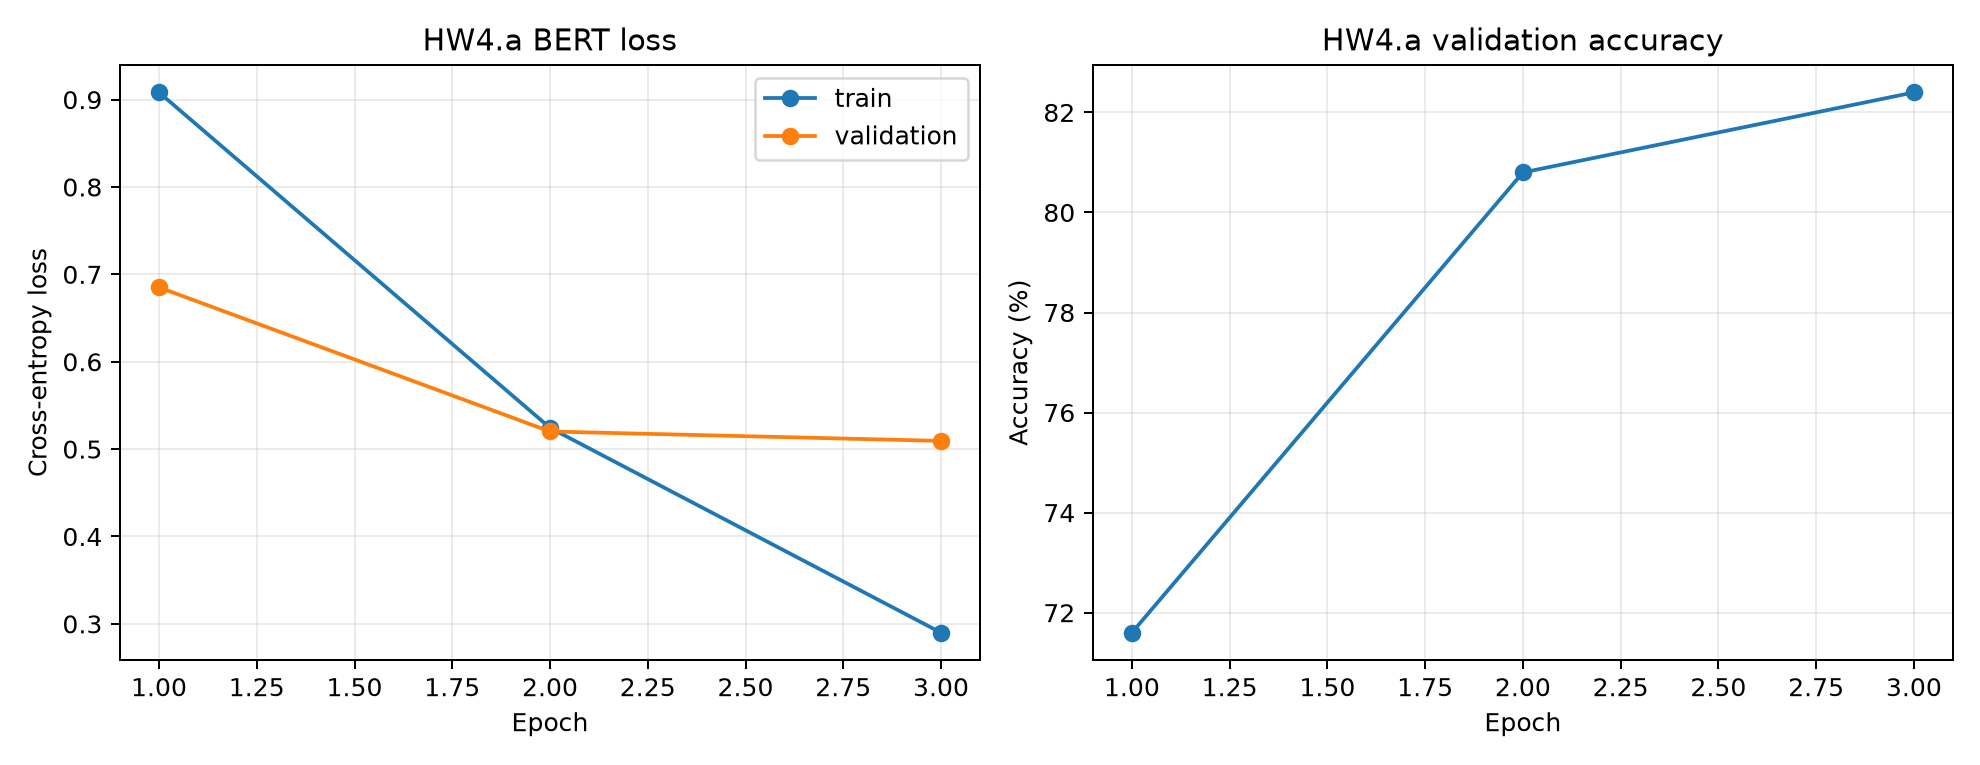

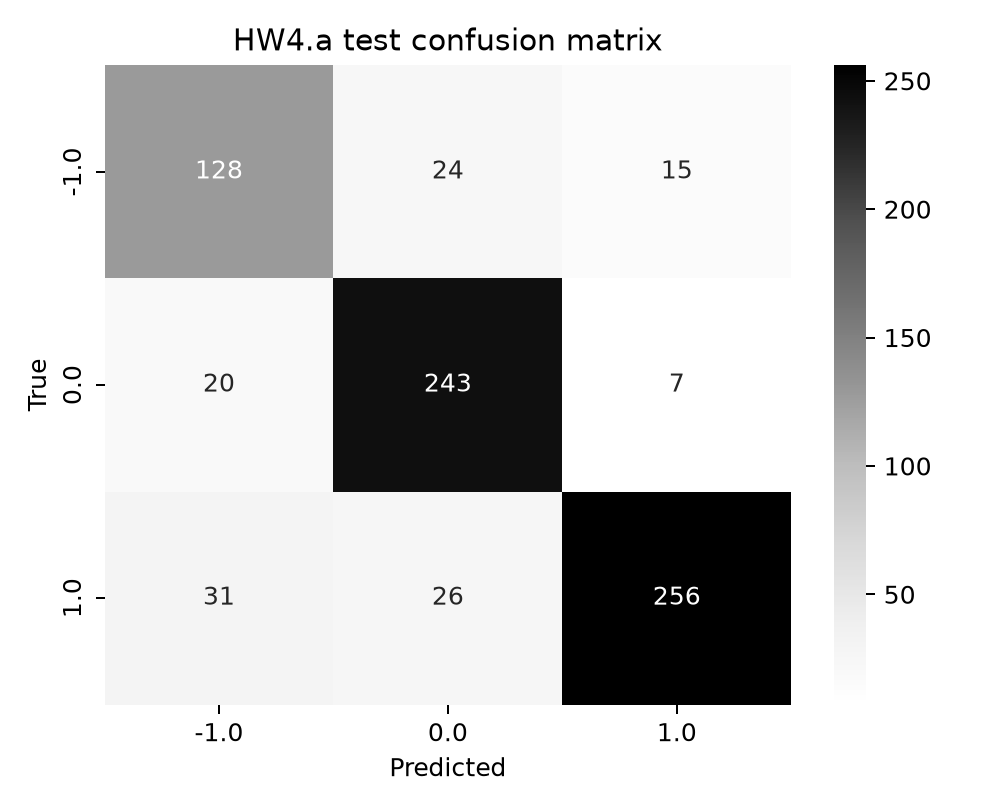

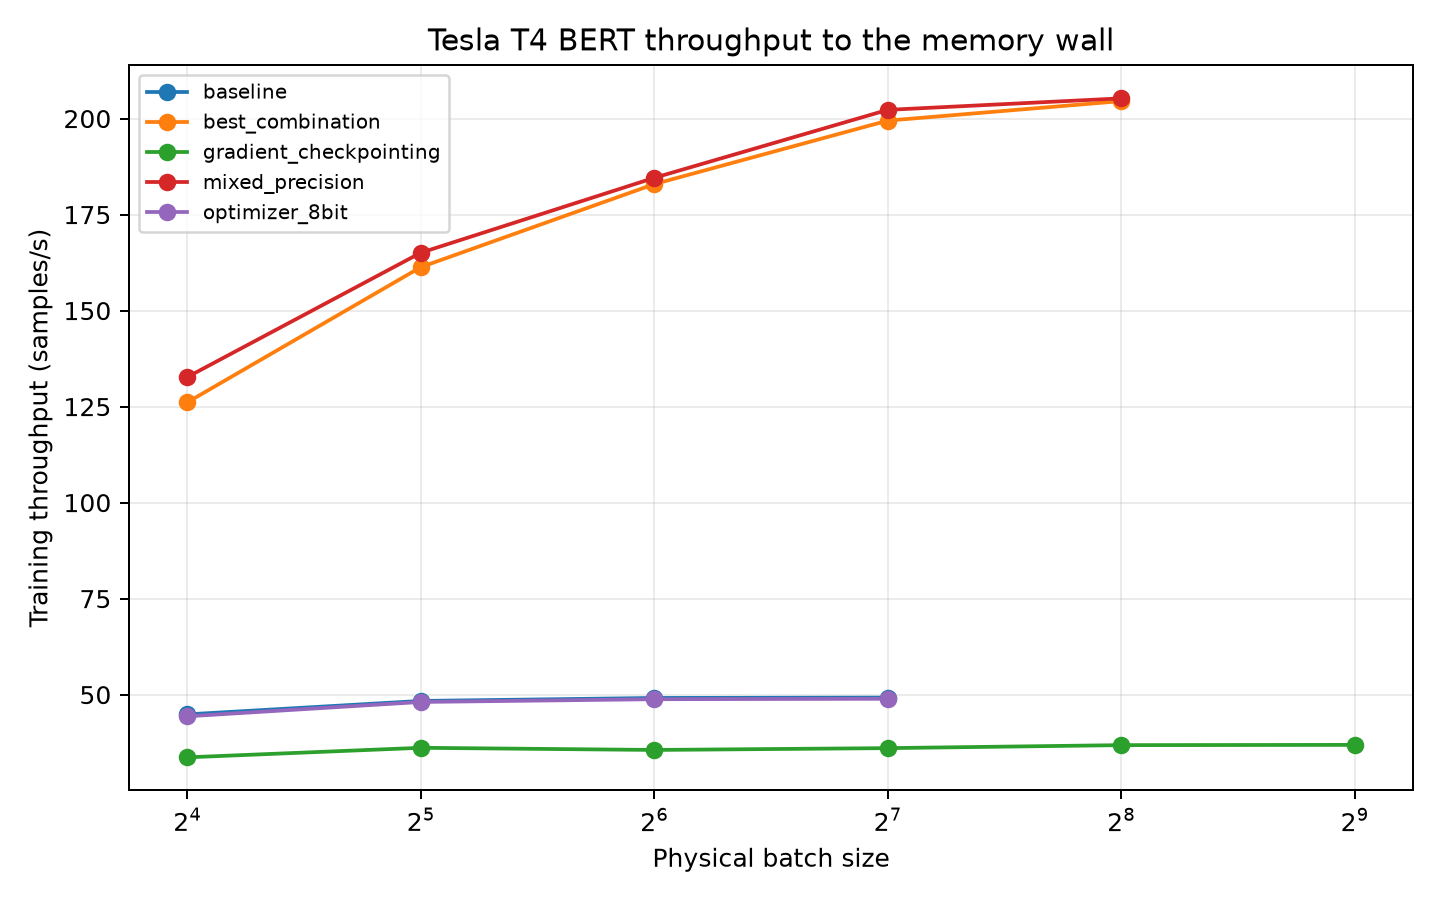

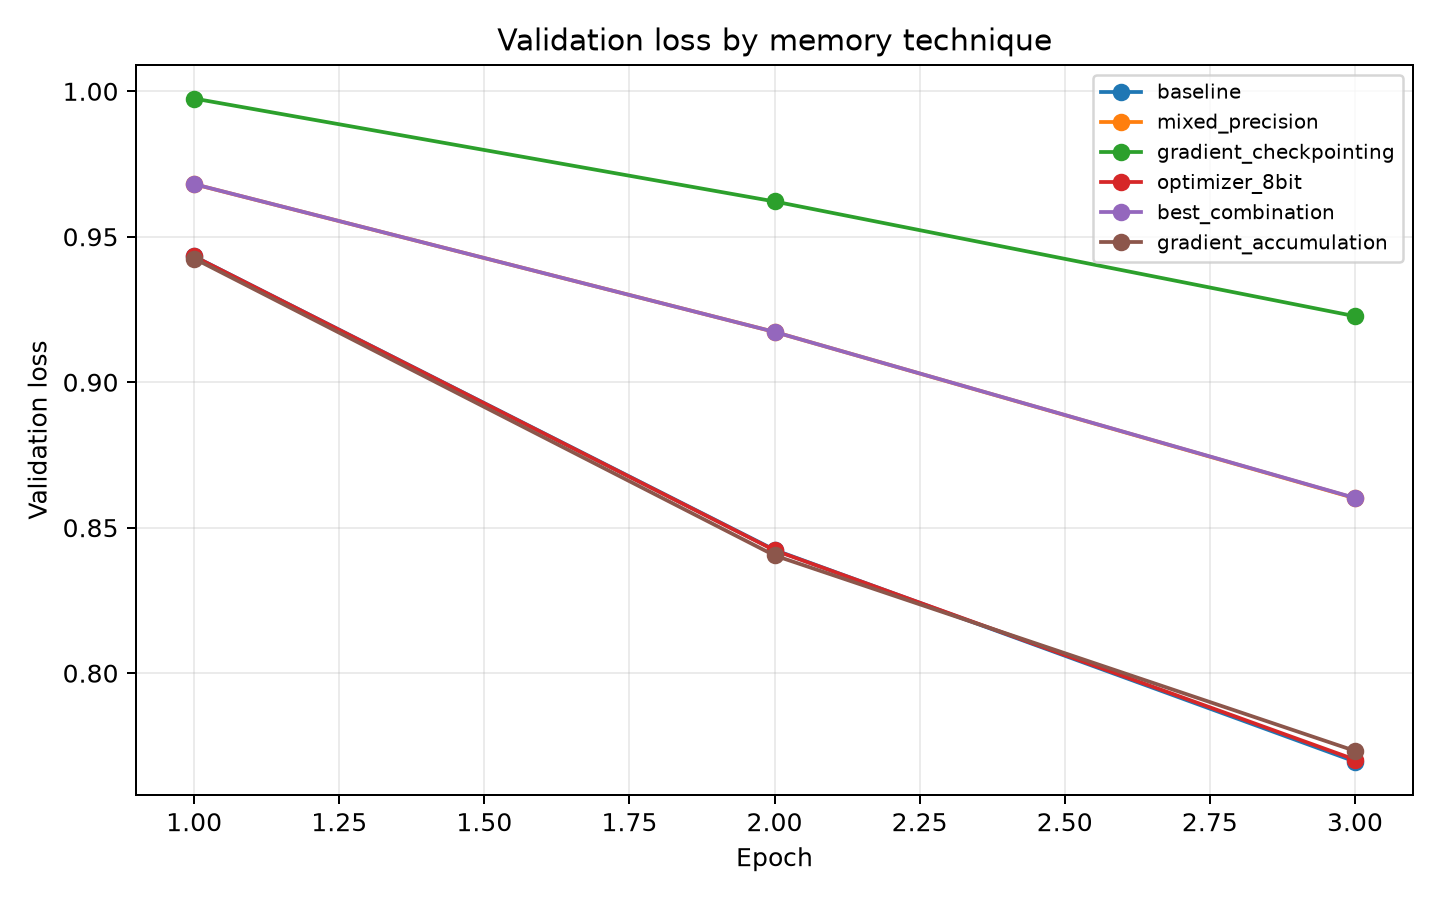

In [8]:
import pandas as pd
from IPython.display import Image, Markdown, display

for name in ("hw4a_epoch_metrics.csv", "hw4a_per_class_metrics.csv", "hw4a_custom_inference.csv",
             "technique_comparison.csv", "serving_benchmark.csv", "kv_cache_context.csv"):
    print(name)
    display(pd.read_csv(WORK / "outputs" / name))
for name in ("hw4a_learning_curves.png", "hw4a_confusion_matrix.png", "batch_size_throughput.png",
             "validation_loss_by_technique.png"):
    display(Image(filename=str(WORK / "outputs" / name)))


## Verify and package the results

The archive includes the full BERT checkpoint so it can be uploaded with the results or shared separately. Colab does not require a lab reservation; actual run timestamps and GPU evidence are recorded automatically. Download this executed notebook with **File → Download → Download .ipynb** as well. A passing computational check does not replace reviewing the written analysis or publishing the final repository tag.

In [9]:
training = json.loads((WORK / "outputs" / "training_summary.json").read_text())
baseline = json.loads((WORK / "outputs" / "hw4a_training_summary.json").read_text())
serving_result = json.loads((WORK / "outputs" / "serving_summary.json").read_text())
prior = json.loads((WORK / "hw4a_baseline.json").read_text())
checks = {
    "HW4.a and HW4.5 used the same dataset hash": baseline["dataset_manifest"]["source_sha256"] == training["dataset_manifest"]["source_sha256"],
    "HW4.a and HW4.5 used identical data settings": baseline["dataset_manifest"]["preparation_settings"] == training["dataset_manifest"]["preparation_settings"],
    "source rows begin at 834": manifest["requested_row_range_zero_based"][0] == 834,
    "fixed 70/15/15 split": manifest["split_ratio"] == "70/15/15",
    "BERT saved and reloaded": len(baseline["reloaded_custom_inference"]) == 2,
    "original measured baseline populated": prior["training_wall_seconds"] > 0,
    "five worst-class HW4.a mistakes available": len(baseline["training"]["five_worst_class_mistakes"]) == 5,
    "all technique sweeps reached OOM": all(any(row["technique"] == name and row["status"] == "oom" for row in training["batch_scaling"]) for name in training["maximum_batches"]),
    "same accumulation optimizer-step count": training["full_runs"]["gradient_accumulation"]["optimizer_steps"] == training["full_runs"]["baseline"]["optimizer_steps"],
    "vLLM batches 1,8,32 measured": [row["batch_size"] for row in serving_result["vllm"]["metrics"]] == [1,8,32],
    "context results exist": len(serving_result["vllm"]["context_results"]) > 0,
    "optional Part C skip recorded": "Part C skipped (optional)" in (WORK / "METRICS.md").read_text(),
    "both GPU UUID captures exist": all((WORK / "outputs" / name).exists() for name in ("gpu_uuid_before.txt", "gpu_uuid_after.txt")),
}
for label, passed in checks.items():
    print(("PASS" if passed else "FAIL") + ": " + label)
(WORK / "verification.json").write_text(json.dumps(checks, indent=2))
assert all(checks.values()), "A requirement check failed. The measurements remain available for inspection."

end = datetime.now(timezone.utc).isoformat()
start_marker = json.loads((WORK / ".complete_smoke.json").read_text())["completed_utc"]
(WORK / "RESERVATION_RECORD.md").write_text(
    "# Runtime record\n\nProvider: Google Colab hosted GPU runtime, or Linux GPU runtime when executed locally.\n"
    "Lab reservation: not applicable for this hosted/personal runtime.\n"
    f"GPU: {hardware['gpu']}\n\nFirst completed smoke check (UTC): {start_marker}\n\nCompleted (UTC): {end}\n\n"
    + gpu_listing)
(WORK / "MODEL_CHECKPOINT.md").write_text(
    "# Saved BERT checkpoint\n\nThe full checkpoint and tokenizer are included in this results archive under "
    "`gpu-ii/checkpoints/hw4a_bert_classifier/`. The saved model was reloaded and tested.\n\n"
    "Training command: `.venv/bin/python hw4a_training.py --settings settings.json`.\n\n"
    "Before repository submission, upload this large checkpoint to approved storage or Git LFS and record its shareable link here.\n")
for source, target in (("COLAB_RUN_LOG.txt", "RUN_LOG.txt"), ("COLAB_RUN_LOG.txt", "RUN_LOG_HW4A.txt")):
    shutil.copy2(WORK / source, WORK / target)

import zipfile
archive = WORK.parent / "GPU_II_RESULTS.zip"
excluded_parts = {".venv", ".setup-tools", "cache", "__pycache__", ".ipynb_checkpoints"}
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_STORED, allowZip64=True) as zipped:
    for path in WORK.rglob("*"):
        relative = path.relative_to(WORK)
        if path.is_file() and not any(part in excluded_parts for part in relative.parts) and path.name != "Twitter_Data.csv":
            zipped.write(path, Path("gpu-ii") / relative)
print("COMPUTATIONAL CHECKLIST PASSED")
print(f"Archive: {archive} ({archive.stat().st_size / 2**20:.1f} MiB)")
print("Save the executed notebook too: File > Download > Download .ipynb.")
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    from IPython.display import FileLink
    display(FileLink(str(archive)))


PASS: HW4.a and HW4.5 used the same dataset hash
PASS: HW4.a and HW4.5 used identical data settings
PASS: source rows begin at 834
PASS: fixed 70/15/15 split
PASS: BERT saved and reloaded
PASS: original measured baseline populated
PASS: five worst-class HW4.a mistakes available
PASS: all technique sweeps reached OOM
PASS: same accumulation optimizer-step count
PASS: vLLM batches 1,8,32 measured
PASS: context results exist
PASS: optional Part C skip recorded
PASS: both GPU UUID captures exist
COMPUTATIONAL CHECKLIST PASSED
Archive: /content/GPU_II_RESULTS.zip (419.6 MiB)
Save the executed notebook too: File > Download > Download .ipynb.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>